# Tarea opcional: punto flotante

## Siete problemas resueltos en Julia

**Autor:** Mateo Gabriel González Lara. **Curso:** Análisis Numérico.

**Solución y código:** Mateo Gabriel González Lara. **Enunciado de la actividad:** material de clase elaborado por [Juan Galvis](https://scholar.google.com/citations?user=lbfc2joAAAAJ&hl=en).

Este cuaderno presenta las soluciones matemáticas, implementaciones, gráficas y mediciones ejecutadas en un kernel Julia real. Las salidas que aparecen debajo de las celdas fueron producidas por Julia; no se presentan comprobaciones externas en Python como si fueran resultados del lenguaje.

**Fuente matemática principal:** Kincaid y Cheney, *Numerical Analysis: Mathematics of Scientific Computing* (2002), edición proporcionada: §1.1, §1.3 (pp. 28–36), §2.1 (pp. 37–54), §2.2 (pp. 55–63) y §2.3 (pp. 64–71). Las páginas indicadas son las impresas en el libro.

En el problema 2 se conserva literalmente la rama del enunciado que incluye $1/2$.


## Preparación y convenciones

El entorno reproducible está registrado en `Project.toml` y `Manifest.toml`. Para reproducirlo desde esta carpeta se ejecuta primero `import Pkg; Pkg.instantiate()` y después se abre el notebook con el kernel `Julia 1.10`.

Se distinguen el resultado exacto, el valor calculado y una referencia de mayor precisión. Para una referencia no nula $r$ se usan
$$E_a=|\widehat y-r|,\qquad E_r=\frac{|\widehat y-r|}{|r|}.$$

`Float64` tiene 53 bits de precisión. Con redondeo al más cercano, su unidad de redondeo es $u=2^{-53}$, mientras que `eps(Float64)=2^{-52}` es la separación entre 1 y su sucesor. El modelo relativo de §2.1 se utiliza cuando no intervienen desbordamiento, subdesbordamiento ni operaciones excepcionales.


In [1]:
import Pkg
Pkg.activate(pwd())
ENV["GKSwstype"] = "100"

using Printf
using Statistics
using InteractiveUtils
using Dates
using BenchmarkTools
using Plots

gr()
default(size=(820, 450), linewidth=2.2, framestyle=:box, legend=:best)

println("Proyecto activo: ", Base.active_project())
println("Versión Julia: ", VERSION)
println("Bytes por Float64: ", sizeof(Float64))
println("eps(Float64): ", eps(Float64))
println("Unidad de redondeo: ", eps(Float64) / 2)


  Activating project at `C:\Users\gabla\Documents\GitHub\Analisis-Numerico\Tareas Opcionales\Tarea opcional punto flotante`


Proyecto activo: C:\Users\gabla\Documents\GitHub\Analisis-Numerico\Tareas Opcionales\Tarea opcional punto flotante\Project.toml
Versión Julia: 1.10.5
Bytes por Float64: 8


eps(Float64): 2.220446049250313e-16
Unidad de redondeo: 1.1102230246251565e-16


## Problema 1. Memoria

**Enunciado.** ¿Cuánta memoria requieren 100 000 números de doble precisión y una matriz de dimensión $100\,000\times100\,000$?

Cada `Float64` ocupa $64/8=8$ bytes. Por tanto,
$$M_v=100\,000(8)=800\,000\ \text{bytes}=0.8\ \text{MB}=781.25\ \text{KiB},$$
$$M_A=(100\,000)^2(8)=80\,000\,000\,000\ \text{bytes}=80\ \text{GB}\approx74.505806\ \text{GiB}.$$

Se usan $1\text{ MB}=10^6$ bytes, $1\text{ GB}=10^9$ bytes y $1\text{ GiB}=2^{30}$ bytes. Se cuenta el contenido numérico de un arreglo denso, sin metadatos del contenedor. No se construye la matriz: el producto de dimensiones basta. Se verifica el tamaño de los datos con un vector pequeño.


In [2]:
function memoria_float64(N::Integer)
    N > 0 || throw(ArgumentError("N debe ser positivo"))
    bytes = sizeof(Float64)
    return (vector=big(N) * bytes, matriz=big(N)^2 * bytes)
end

memoria_p1 = memoria_float64(100_000)
println("Vector: ", memoria_p1.vector, " bytes = ",
        Float64(memoria_p1.vector) / 10^6, " MB = ",
        Float64(memoria_p1.vector) / 2^10, " KiB")
println("Matriz: ", memoria_p1.matriz, " bytes = ",
        Float64(memoria_p1.matriz) / 10^9, " GB = ",
        Float64(memoria_p1.matriz) / 2^30, " GiB")

vector_control = zeros(Float64, 100)
@assert sizeof(vector_control) == 100 * sizeof(Float64)
@assert memoria_p1.vector == 800_000
@assert memoria_p1.matriz == 80_000_000_000


Vector: 800000 bytes = 0.8 MB = 781.25 KiB
Matriz: 80000000000 bytes = 80.0 GB = 74.50580596923828 GiB

## Problema 2. Sucesión por tramos (Sullivan)

**Enunciado.** Con $x_0=1/10$ y, después, con $x_0=1/8$, calcular analíticamente y mediante código $x_1,\ldots,x_{50}$, donde
$$T(x)=\begin{cases}2x,&0\le x\le1/2,\\2x-1,&1/2<x\le1.\end{cases}$$

**Solución exacta para $x_0=1/10$.** Los primeros valores son
$$x_1=\tfrac15,\quad x_2=\tfrac25,\quad x_3=\tfrac45,\quad x_4=\tfrac35,\quad x_5=\tfrac15.$$
Como $T$ es una función, la repetición de $x_1$ obliga a repetir los valores siguientes. Así, para todo entero $q\ge0$,
$$x_{4q+1}=\tfrac15,\quad x_{4q+2}=\tfrac25,\quad x_{4q+3}=\tfrac45,\quad x_{4q+4}=\tfrac35.$$
Esto determina todos los valores pedidos y da $x_{50}=2/5$.

**Representación inicial y propagación.** Un racional reducido tiene expansión binaria finita si y solo si su denominador es una potencia de 2; esto se obtiene al escribir una expansión binaria finita sobre un denominador $2^p$, y recíprocamente. Por tanto, $1/10$ no es representable exactamente y $1/8$ sí lo es. En `Float64`, con redondeo al más cercano,
$$\widehat x_0-\tfrac1{10}=\frac1{5\cdot2^{55}}.$$
Mientras ambos recorridos sigan la misma rama, $\widehat x_{n+1}-x_{n+1}=2(\widehat x_n-x_n)$, si la operación es exacta. Para los primeros 50 pasos de este ejemplo las operaciones con el dato binario almacenado son exactas y las ramas coinciden, lo cual también se verifica con racionales en el código. Por tanto,
$$\widehat x_{50}-x_{50}=\frac{2^{50}}{5\cdot2^{55}}=\frac1{160},\qquad \widehat x_{50}=0.40625.$$
El error observado hasta ese punto se debe a la amplificación del error inicial; no hace falta atribuirlo a nuevo redondeo en cada paso. No se extiende la igualdad de errores sin comprobar las ramas, porque $T$ es discontinua en $1/2$.

**Solución para $x_0=1/8$.** Se obtiene exactamente
$$x_1=\tfrac14,\quad x_2=\tfrac12,\quad x_n=1\quad(n\ge3).$$
La rama del enunciado incluye $1/2$ en el primer caso. Sustituirla por el mapa usual módulo 1 cambiaría la respuesta. Todos estos valores son representables exactamente en binario y las operaciones indicadas conservan su exactitud.

**Fundamento:** representación binaria de §2.1 y propagación de perturbaciones de §2.3.


In [3]:
function orbita(x0, N::Integer)
    N >= 0 || throw(ArgumentError("N debe ser no negativo"))
    zero(x0) <= x0 <= one(x0) || throw(ArgumentError("x0 fuera de [0,1]"))
    xs = Vector{typeof(x0)}(undef, N + 1)
    xs[1] = x0
    for n in 1:N
        x = xs[n]
        # La igualdad 2x == 1 pertenece a la primera rama del enunciado.
        xs[n + 1] = 2 * x <= one(x) ? 2 * x : 2 * x - one(x)
    end
    xs
end

function tabla_orbita(q0::Rational, N=50)
    exactos = orbita(q0, N)
    flotantes = orbita(Float64(q0), N)
    println(" n      exacto                Float64             error absoluto")
    setprecision(BigFloat, 256) do
        for n in 1:N
            error = abs(BigFloat(flotantes[n + 1]) - BigFloat(exactos[n + 1]))
            @printf("%2d  %10s  % .17e  %.5e\n", n, string(exactos[n + 1]),
                    flotantes[n + 1], Float64(error))
        end
    end
    (exactos=exactos, flotantes=flotantes)
end

orbitas10 = tabla_orbita(big(1) // big(10))
orbitas8 = tabla_orbita(big(1) // big(8))

let q10 = big(1) // big(10), qhat = Rational{BigInt}(0.1)
    @assert qhat - q10 == big(1) // (big(5) * big(2)^55)
    exactos_dato_almacenado = orbita(qhat, 50)
    @assert all(Rational{BigInt}(orbitas10.flotantes[j]) == exactos_dato_almacenado[j] for j in 1:51)
    @assert all((2 * orbitas10.exactos[j] <= 1) == (2 * exactos_dato_almacenado[j] <= 1) for j in 1:50)
    @assert orbitas10.exactos[51] == big(2) // big(5)
    @assert orbitas10.flotantes[51] == 0.40625
    @assert orbitas8.exactos[3] == big(1) // big(2)
    @assert orbitas8.exactos[4] == 1
    @assert all(Rational{BigInt}(orbitas8.flotantes[j]) == orbitas8.exactos[j] for j in 1:51)
end

println("Verificación final x₀=1/10: x₅₀ exacto = ", orbitas10.exactos[51],
        " = ", Float64(orbitas10.exactos[51]),
        "; Float64 = ", orbitas10.flotantes[51])
println("Verificación de la rama x₀=1/8: x₂ = ", orbitas8.exactos[3],
        ", x₃ = ", orbitas8.exactos[4])


 n      exacto                Float64             error absoluto


 1        1//5   2.00000000000000011e-01  1.11022e-17
 2        2//5   4.00000000000000022e-01  2.22045e-17
 3        4//5   8.00000000000000044e-01  4.44089e-17
 4        3//5   6.00000000000000089e-01  8.88178e-17
 5        1//5   2.00000000000000178e-01  1.77636e-16
 6        2//5   4.00000000000000355e-01  3.55271e-16
 7        4//5   8.00000000000000711e-01  7.10543e-16
 8        3//5   6.00000000000001421e-01  1.42109e-15
 9        1//5   2.00000000000002842e-01  2.84217e-15
10        2//5   4.00000000000005684e-01  5.68434e-15
11        4//5   8.00000000000011369e-01  1.13687e-14
12        3//5   6.00000000000022737e-01  2.27374e-14
13        1//5   2.00000000000045475e-01  4.54747e-14
14        2//5   4.00000000000090949e-01  9.09495e-14
15        4//5   8.00000000000181899e-01  1.81899e-13
16        3//5   6.00000000000363798e-01  3.63798e-13
17        1//5   2.00000000000727596e-01  7.27596e-13
18        2//5   4.00000000001455192e-01  1.45519e-12
19        4//5   8.000000000

Verificación final x₀=1/10: x₅₀ exacto = 2//5 = 0.4; Float64 = 0.40625
Verificación de la rama x₀=1/8: x₂ = 1//2, x₃ = 1//1


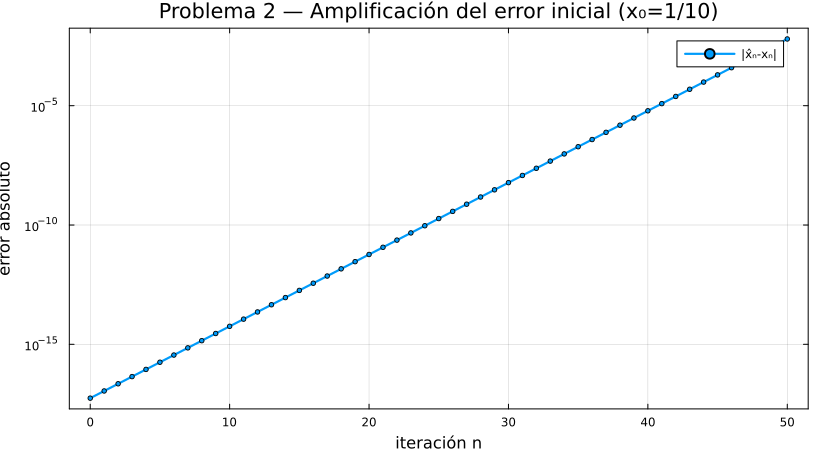

In [4]:
errores_orbita10 = setprecision(BigFloat, 256) do
    [Float64(abs(BigFloat(orbitas10.flotantes[n + 1]) - BigFloat(orbitas10.exactos[n + 1]))) for n in 0:50]
end

grafica_p2 = plot(0:50, errores_orbita10;
    yscale=:log10, marker=:circle, markersize=2.5,
    xlabel="iteración n", ylabel="error absoluto",
    title="Problema 2 — Amplificación del error inicial (x₀=1/10)",
    label="|x̂ₙ-xₙ|")
display(grafica_p2)


## Problema 3. Softmax sin desbordamiento por exceso (Goodfellow et al.)

**Enunciado.** Implementar de forma estabilizada
$$SF_i(x)=\frac{e^{x_i}}{\sum_{j=1}^n e^{x_j}}.$$

**Dominio del programa:** vector no vacío de números finitos en punto flotante. Sea $a=\max_jx_j$. Dividir numerador y denominador por $e^a$ da
$$SF_i(x)=\frac{e^{x_i-a}}{\sum_{j=1}^n e^{x_j-a}}.$$
Como $x_i-a\le0$, los exponenciales están entre 0 y 1, y algún término es 1. Se evita así el desbordamiento por exceso de los exponenciales y el denominador no es cero. En aritmética exacta todas las componentes son positivas y suman 1; en punto flotante la suma es aproximada y componentes extremadamente pequeñas pueden subdesbordar a cero. Esto no garantiza exactitud relativa de probabilidades arbitrariamente pequeñas. En un vector tan grande que su longitud superara el rango del acumulador, también habría que estudiar la suma; no ocurre en los experimentos propuestos.

La identidad se demuestra aquí por álgebra; §2.1 explica los límites de representación y §2.2–2.3 fundamentan comparar formulaciones equivalentes por su comportamiento numérico. No se afirma que el libro presente softmax.


In [5]:
softmax_directa(x::AbstractVector{<:AbstractFloat}) = exp.(x) ./ sum(exp.(x))

function softmax_estable(x::AbstractVector{T}) where {T<:AbstractFloat}
    isempty(x) && throw(ArgumentError("El vector no puede estar vacío"))
    all(isfinite, x) || throw(ArgumentError("Se requieren entradas finitas"))
    a = maximum(x)
    y = exp.(x .- a)
    y ./ sum(y)
end

let casos = ([1.0, 2.0, 3.0], [1000.0, 1001.0, 1002.0], [-1000.0, -1001.0, -1002.0])
    for x in casos
        directa = softmax_directa(x)
        estable = softmax_estable(x)
        println("x = ", x)
        println("Directa: ", directa)
        println("Estable: ", estable, "; suma = ", sum(estable))
        @assert all(isfinite, estable)
        @assert all(t -> t >= 0, estable)
        @assert isapprox(sum(estable), 1.0; atol=10 * eps(Float64), rtol=0)
    end
end

let p = softmax_estable([1000.0, 1001.0, 1002.0]),
    q = softmax_estable([0.0, 1.0, 2.0])
    @assert isapprox(p, q; atol=10 * eps(Float64), rtol=0)
end


x = 

[1.0, 2.0, 3.0]
Directa: [0.09003057317038046, 0.24472847105479767, 0.6652409557748219]
Estable: [0.09003057317038046, 0.24472847105479764, 0.6652409557748218]; suma = 0.9999999999999999
x = [1000.0, 1001.0, 1002.0]
Directa: [NaN, NaN, NaN]
Estable: [0.09003057317038046, 0.24472847105479764, 0.6652409557748218]; suma = 0.9999999999999999
x = [-1000.0, -1001.0, -1002.0]
Directa: [NaN, NaN, NaN]
Estable: [0.6652409557748218, 0.24472847105479764, 0.09003057317038046]; suma = 0.9999999999999999


## Problema 4. Cancelación en dos expresiones equivalentes (Stoer)

**Enunciado.** Comparar, para $x=8^{-1},8^{-2},\ldots$,
$$f(x)=\sqrt{1+x^2}-1,\qquad g(x)=\frac{x^2}{\sqrt{1+x^2}+1}.$$

Multiplicar por el conjugado demuestra $f(x)=g(x)$ para todo real $x$, porque $\sqrt{1+x^2}+1>0$. Sin embargo, cuando $x$ es pequeño, la primera fórmula resta números casi iguales. Puesto que $\sqrt{1+x^2}-1\sim x^2/2$, un error absoluto de orden $u$ en la raíz puede producir un error relativo de orden $u/x^2$. La fórmula racionalizada evita esa resta.

En `Float64`, para $k=9$, $x=8^{-9}=2^{-27}$ y $x^2=2^{-54}$; redondear $1+2^{-54}$ al más cercano produce 1. Así, la primera fórmula devuelve cero, aunque el valor matemático es positivo. La segunda conserva un resultado positivo cercano a $2^{-55}$. La referencia de 256 bits se calcula también con la fórmula racionalizada, sin convertir primero una referencia calculada en `Float64`.

Esta reformulación coincide con el ejemplo 1 de §2.2, p. 56, y el experimento es el problema computacional 1 de esa sección, p. 62. La aplicación cuantitativa del teorema de pérdida de precisión, §2.2, p. 57, debe distinguir la resta de dos números de máquina del error ya introducido al evaluar la raíz.

El análisis se limita a $1\le k\le30$; para valores muchísimo menores también sería necesario estudiar el subdesbordamiento de $x^2$. No se afirma que la fórmula racionalizada elimine todos los errores para cualquier entrada.


In [6]:
f_cancelacion(x) = sqrt(one(x) + x * x) - one(x)
g_racionalizada(x) = (x * x) / (sqrt(one(x) + x * x) + one(x))

datos_cancelacion = setprecision(BigFloat, 256) do
    filas = NamedTuple[]
    for k in 1:30
        x = ldexp(1.0, -3 * k) # x = 8^(-k), exactamente en binario
        referencia = g_racionalizada(BigFloat(x))
        fx, gx = f_cancelacion(x), g_racionalizada(x)
        error_f = abs(BigFloat(fx) - referencia) / abs(referencia)
        error_g = abs(BigFloat(gx) - referencia) / abs(referencia)
        push!(filas, (k=k, x=x, f=fx, g=gx,
                      error_f=Float64(error_f), error_g=Float64(error_g)))
    end
    filas
end

println(" k         x                f(x)              g(x)          Er(f)       Er(g)")
for r in datos_cancelacion
    @printf("%2d  %.6e  %.10e  %.10e  %.3e  %.3e\n",
            r.k, r.x, r.f, r.g, r.error_f, r.error_g)
end

@assert datos_cancelacion[8].f > 0.0
@assert datos_cancelacion[9].f == 0.0
@assert all(r.f == 0.0 for r in datos_cancelacion[9:end])
@assert all(r.g > 0.0 for r in datos_cancelacion)
println("Primer k con f(x)=0 en Float64: ", findfirst(r -> r.f == 0.0, datos_cancelacion))


 k         x                f(x)              g(x)          Er(f)       Er(g)


 1  1.250000e-01  7.7822185373e-03  7.7822185373e-03  8.366e-15  7.143e-18
 2  1.562500e-02  1.2206286283e-04  1.2206286283e-04  6.824e-13  8.324e-17
 3  1.953125e-03  1.9073468138e-06  1.9073468138e-06  1.819e-12  4.337e-18
 4  2.441406e-04  2.9802321944e-08  2.9802321944e-08  4.441e-16  1.654e-23
 5  3.051758e-05  4.6566128731e-10  4.6566128720e-10  2.328e-10  1.084e-19
 6  3.814697e-06  7.2759576142e-12  7.2759576142e-12  3.638e-12  2.647e-23
 7  4.768372e-07  1.1368683772e-13  1.1368683772e-13  5.684e-14  6.462e-27
 8  5.960464e-08  1.7763568394e-15  1.7763568394e-15  8.882e-16  1.578e-30
 9  7.450581e-09  0.0000000000e+00  2.7755575616e-17  1.000e+00  1.388e-17
10  9.313226e-10  0.0000000000e+00  4.3368086899e-19  1.000e+00  2.168e-19
11  1.164153e-10  0.0000000000e+00  6.7762635780e-21  1.000e+00  3.388e-21
12  1.455192e-11  0.0000000000e+00  1.0587911841e-22  1.000e+00  5.294e-23
13  1.818989e-12  0.0000000000e+00  1.6543612251e-24  1.000e+00  8.272e-25
14  2.273737e-13  0.00000

Primer k con f(x)=0 en Float64: 9


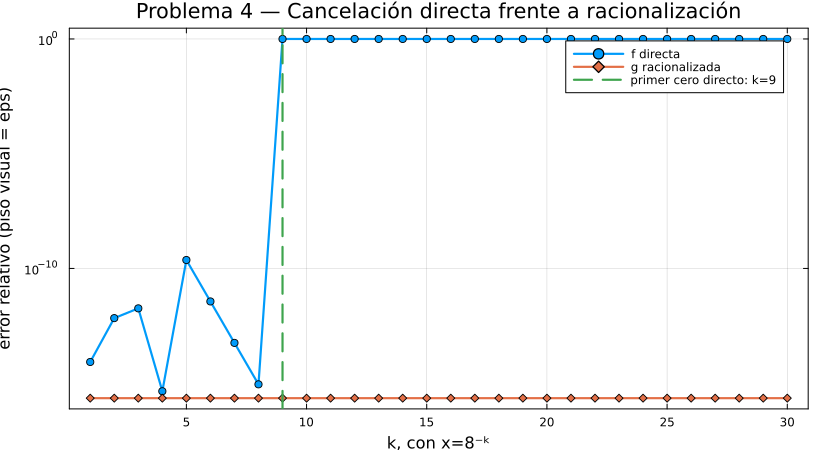

In [7]:
piso_visual = eps(Float64)
grafica_p4 = plot([r.k for r in datos_cancelacion],
    max.([r.error_f for r in datos_cancelacion], piso_visual);
    yscale=:log10, marker=:circle, xlabel="k, con x=8⁻ᵏ",
    ylabel="error relativo (piso visual = eps)",
    title="Problema 4 — Cancelación directa frente a racionalización",
    label="f directa")
plot!(grafica_p4, [r.k for r in datos_cancelacion],
    max.([r.error_g for r in datos_cancelacion], piso_visual);
    marker=:diamond, label="g racionalizada")
vline!(grafica_p4, [9]; linestyle=:dash, label="primer cero directo: k=9")
display(grafica_p4)


## Problema 5. Recurrencia de Viète: indexación y estabilidad (Quarteroni, Saleri y Gervasio)

La recurrencia estudiada aproxima $\pi$. Para implementarla de forma continua usamos la reindexación $w_k=z_{k+1}$, con
$$w_1=2,\qquad w_{k+1}=2^{k+1/2}\sqrt{1-\sqrt{1-4^{-k}w_k^2}},\quad k\ge1.$$

Esta sucesión satisface
$$w_k=2^k\sin\!\left(\frac{\pi}{2^k}\right).$$
En efecto, si $\theta=\pi/2^k$, entonces $4^{-k}w_k^2=\sin^2\theta$. Como $\theta\in(0,\pi/2]$, se tiene $\sqrt{1-\sin^2\theta}=\cos\theta$ y
$$1-\cos\theta=2\sin^2\!\left(\frac{\theta}{2}\right).$$
Al sustituir esta identidad en la recurrencia se obtiene la misma fórmula para $w_{k+1}$. Además, como $\sin t/t\to1$ cuando $t\to0$,
$$w_k=\pi\,\frac{\sin(\pi/2^k)}{\pi/2^k}\longrightarrow\pi.$$

La fórmula directa contiene la resta $1-\sqrt{1-a_k}$, donde $a_k=4^{-k}w_k^2$. A medida que $k$ crece, esa resta ocurre entre números cada vez más cercanos y pierde cifras significativas. Racionalizando,
$$1-\sqrt{1-a_k}=\frac{a_k}{1+\sqrt{1-a_k}},$$
se obtiene la forma más estable
$$\boxed{w_{k+1}=w_k\sqrt{\frac{2}{1+\sqrt{1-a_k}}}.}$$

Las dos expresiones son equivalentes en aritmética exacta, pero no se comportan igual en `Float64`. La comparación numérica muestra cuándo la forma directa empieza a perder información y cuánto tiempo conserva precisión la versión racionalizada. Por Taylor,
$$\pi-w_k=\frac{\pi^3}{6\,4^k}+O(16^{-k}),$$
de modo que al principio el error disminuye aproximadamente por un factor de cuatro; después termina dominando el redondeo.


In [8]:
function viete(N::Integer, ::Type{T}=Float64; estable=false) where {T<:AbstractFloat}
    N >= 1 || throw(ArgumentError("N debe ser al menos 1"))
    w = Vector{T}(undef, N)
    w[1] = T(2)
    for k in 1:N-1
        a = ldexp(w[k], -k)^2
        radicando = one(T) - a
        radicando >= zero(T) || throw(DomainError(radicando, "Radicando negativo; revisar índice o redondeo"))
        interior = sqrt(radicando)
        if estable
            w[k + 1] = w[k] * sqrt(T(2) / (one(T) + interior))
        else
            # Forma propuesta, reindexada como w_k=z_{k+1}.
            w[k + 1] = ldexp(sqrt(T(2) * (one(T) - interior)), k)
        end
    end
    w
end

viete_directa64 = viete(40)
viete_estable64 = viete(40; estable=true)
datos_viete = setprecision(BigFloat, 256) do
    pi_ref = BigFloat(pi)
    [(k=k, directa=viete_directa64[k], estable=viete_estable64[k],
      error_directa=Float64(abs(BigFloat(viete_directa64[k]) - pi_ref)),
      error_estable=Float64(abs(BigFloat(viete_estable64[k]) - pi_ref))) for k in 1:40]
end

println(" k       directa             estable           Ea(directa)   Ea(estable)")
for r in datos_viete
    @printf("%2d  %.16e  %.16e  %.4e  %.4e\n",
            r.k, r.directa, r.estable, r.error_directa, r.error_estable)
end
@assert isapprox(viete_estable64[end], Float64(pi); atol=20 * eps(Float64), rtol=0)
println("Primer índice k donde la forma directa devuelve cero: ",
        findfirst(iszero, viete_directa64))

setprecision(BigFloat, 256) do
    alta = viete(80, BigFloat; estable=true)
    println("Error estable a 256 bits, k=80: ", abs(alta[end] - BigFloat(pi)))
end


 k       directa             estable           Ea(directa)   Ea(estable)


 1  2.0000000000000000e+00  2.0000000000000000e+00  1.1416e+00  1.1416e+00
 2  2.8284271247461903e+00  2.8284271247461903e+00  3.1317e-01  3.1317e-01
 3  3.0614674589207187e+00  3.0614674589207187e+00  8.0125e-02  8.0125e-02
 4  3.1214451522580529e+00  3.1214451522580529e+00  2.0148e-02  2.0148e-02
 5  3.1365484905459406e+00  3.1365484905459398e+00  5.0442e-03  5.0442e-03
 6  3.1403311569547392e+00  3.1403311569547534e+00  1.2615e-03  1.2615e-03
 7  3.1412772509327569e+00  3.1412772509327733e+00  3.1540e-04  3.1540e-04
 8  3.1415138011441455e+00  3.1415138011443013e+00  7.8852e-05  7.8852e-05
 9  3.1415729403678827e+00  3.1415729403670913e+00  1.9713e-05  1.9713e-05
10  3.1415877252799609e+00  3.1415877252771596e+00  4.9283e-06  4.9283e-06
11  3.1415914215046352e+00  3.1415914215111997e+00  1.2321e-06  1.2321e-06
12  3.1415923456110768e+00  3.1415923455701176e+00  3.0798e-07  3.0802e-07
13  3.1415925765450043e+00  3.1415925765848725e+00  7.7045e-08  7.7005e-08
14  3.1415926334632482e+

30
Error estable a 256 bits, k=80: 3.535892569704958092685294606427204055551525333554833854261652612326489430851581e-48


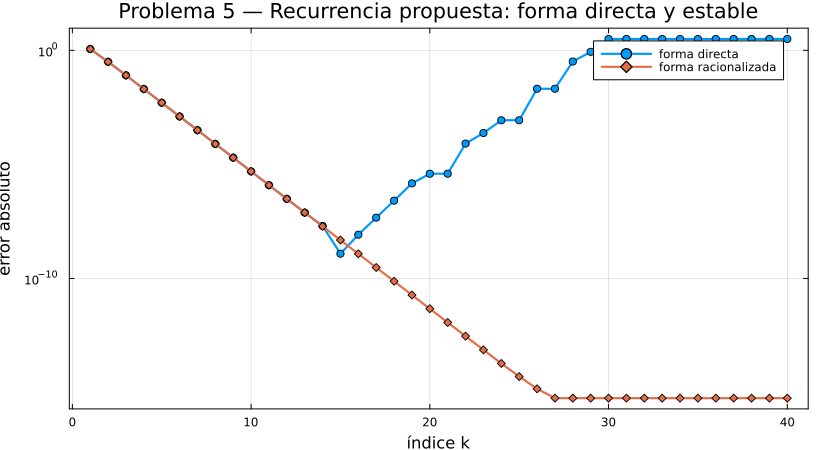

In [9]:
grafica_p5 = plot([r.k for r in datos_viete],
    max.([r.error_directa for r in datos_viete], eps(Float64));
    yscale=:log10, marker=:circle, xlabel="índice k", ylabel="error absoluto",
    title="Problema 5 — Recurrencia propuesta: forma directa y estable",
    label="forma directa")
plot!(grafica_p5, [r.k for r in datos_viete],
    max.([r.error_estable for r in datos_viete], eps(Float64));
    marker=:diamond, label="forma racionalizada")
display(grafica_p5)


## Problema 6. Recurrencia de Stewart

**Enunciado.** Implementar $x_1=1/3$, $x_2=1/12$ y
$$x_{k+1}=2.25x_k-0.5x_{k-1},\qquad k\ge2,$$
y explicar los resultados.

Es una ecuación lineal en diferencias con coeficientes constantes (§1.3). Su polinomio característico es
$$r^2-\tfrac94r+\tfrac12=(r-2)(r-\tfrac14).$$
Las raíces son distintas y no nulas; por la representación de soluciones de §1.3,
$$x_k=A\left(\tfrac14\right)^{k-1}+B\,2^{k-1}.$$
Los datos dan $A+B=1/3$ y $A/4+2B=1/12$, de donde $B=0$ y $A=1/3$. Así,
$$\boxed{x_k=\frac1{3\,4^{k-1}}\longrightarrow0.}$$

**Inestabilidad.** Si los primeros datos cambian en $e_1,e_2$ y después se itera exactamente, el coeficiente de la componente creciente del error es
$$B_e=\frac{4e_2-e_1}{7}.$$
Una componente no nula proporcional a $2^{k-1}$ acaba dominando la solución deseada proporcional a $4^{1-k}$; su importancia relativa crece como $8^{k-1}$. Además, si cada paso introduce una perturbación local $\rho_k$, el error satisface
$$e_{k+1}=\tfrac94e_k-\tfrac12e_{k-1}+\rho_k,$$
lo que permite volver a introducir la componente creciente durante el cálculo. Este es el mecanismo de §2.3: perturbaciones pequeñas amplificadas por la recurrencia.

**Matiz importante.** En `Float64`, los valores iniciales almacenados cumplen exactamente $\widehat x_2=\widehat x_1/4$; sus errores iniciales están correlacionados y cumplen $4e_2-e_1=0$. Por tanto, no es correcto atribuir en este ejemplo toda la componente creciente únicamente al redondeo inicial. El redondeo de las operaciones posteriores la introduce.

Para esta solución concreta, la recurrencia de primer orden $x_{k+1}=x_k/4$, partiendo de $1/3$, evita ese modo creciente y escala exactamente por una potencia de 2 mientras no se encuentre subdesbordamiento. Esta alternativa usa la solución analítica y no reemplaza el análisis de la recurrencia pedida.


In [10]:
function stewart(N::Integer, ::Type{T}=Float64) where {T<:AbstractFloat}
    N >= 2 || throw(ArgumentError("N debe ser al menos 2"))
    x = Vector{T}(undef, N)
    x[1], x[2] = one(T) / T(3), one(T) / T(12)
    for k in 2:N-1
        x[k + 1] = (T(9) / T(4)) * x[k] - (one(T) / T(2)) * x[k - 1]
    end
    x
end

function stewart_alternativa(N::Integer)
    x = Vector{Float64}(undef, N)
    x[1] = 1.0 / 3.0
    for k in 1:N-1
        x[k + 1] = x[k] / 4.0
    end
    x
end

stewart64 = stewart(80)
stewart_alt64 = stewart_alternativa(80)
datos_stewart = setprecision(BigFloat, 256) do
    [(k=k, calculado=stewart64[k], alternativo=stewart_alt64[k],
      referencia=inv(BigFloat(3) * BigFloat(4)^(k - 1)),
      error_relativo=Float64(abs(BigFloat(stewart64[k]) * BigFloat(3) * BigFloat(4)^(k - 1) - 1))) for k in 1:80]
end

println(" k       recurrencia          referencia          alternativa      Er(recurrencia)")
for k in (1, 2, 3, 10, 20, 30, 40, 50, 80)
    r = datos_stewart[k]
    @printf("%2d  %.12e  %.12e  %.12e  %.4e\n",
            r.k, r.calculado, Float64(r.referencia), r.alternativo, r.error_relativo)
end

# Los errores iniciales están correlacionados: 4e₂-e₁=0 exactamente.
q1, q2 = Rational{BigInt}(stewart64[1]), Rational{BigInt}(stewart64[2])
e1 = q1 - big(1) // big(3)
e2 = q2 - big(1) // big(12)
@assert stewart64[2] == stewart64[1] / 4
@assert 4 * e2 - e1 == 0
println("Errores iniciales exactos: e₁=", e1, ", e₂=", e2,
        "; 4e₂-e₁=", 4 * e2 - e1)

# La primera operación ya introduce una perturbación local no nula.
x3_operacion_exacta = (big(9) // 4) * q2 - (big(1) // 2) * q1
rho3 = Rational{BigInt}(stewart64[3]) - x3_operacion_exacta
@assert rho3 != 0
println("Perturbación local de redondeo en x₃: ρ₃=", rho3)

setprecision(BigFloat, 256) do
    alta = stewart(80, BigFloat)
    println("Error relativo a 256 bits, k=80: ",
            abs(alta[end] * BigFloat(3) * BigFloat(4)^79 - 1))
end


 k       recurrencia          referencia          alternativa      Er(recurrencia)
 1  3.333333333333e-01  3.333333333333e-01  3.333333333333e-01  5.5511e-17
 2  8.333333333333e-02  8.333333333333e-02  8.333333333333e-02  5.5511e-17
 3  2.083333333333e-02  2.083333333333e-02  2.083333333333e-02  4.4409e-16
10  1.271565756731e-06  1.271565755208e-06  1.271565755208e-06  1.1974e-09
20  2.771793376832e-12  1.212659602364e-12  1.212659602364e-12  1.2857e+00
30  1.596552986212e-09  1.156482317318e-18  1.156482317318e-18  1.3805e+09
40  1.634870256696e-06  1.102907483404e-24  1.102907483404e-24  1.4823e+18
50  1.674107142857e-03  1.051814540295e-30  1.051814540295e-30  1.5916e+27
80  1.797558857143e+06  9.123036877115e-49  9.123036877115e-49  1.9704e+54
Errores iniciales exactos: e₁=-1//54043195528445952, e₂=-1//216172782113783808; 4e₂-e₁=0//1
Perturbación local de redondeo en x₃: ρ₃=3//288230376151711744


Error relativo a 256 bits, k=80: 1.532690865652901785714285714285714285714285714285714285714285714285714187015217e-07


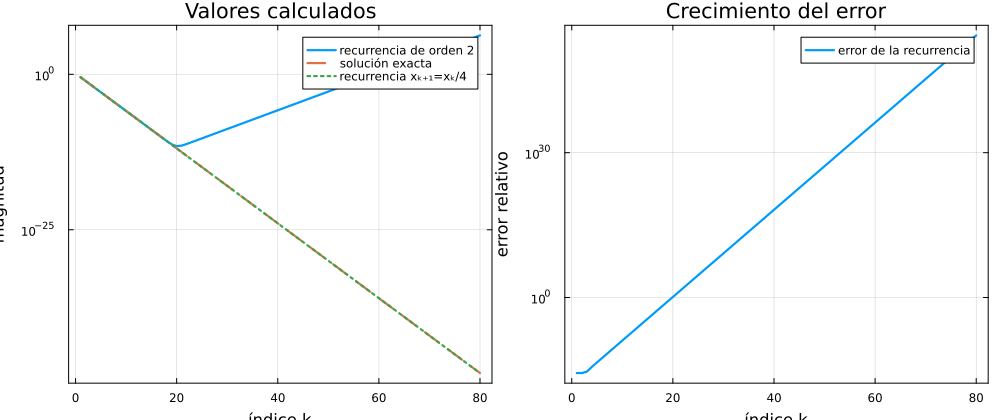

In [11]:
indices_stewart = [r.k for r in datos_stewart]
grafica_p6a = plot(indices_stewart, abs.([r.calculado for r in datos_stewart]);
    yscale=:log10, xlabel="índice k", ylabel="magnitud",
    title="Valores calculados", label="recurrencia de orden 2")
plot!(grafica_p6a, indices_stewart, Float64.([r.referencia for r in datos_stewart]);
    linestyle=:dash, label="solución exacta")
plot!(grafica_p6a, indices_stewart, abs.([r.alternativo for r in datos_stewart]);
    linestyle=:dot, label="recurrencia xₖ₊₁=xₖ/4")

grafica_p6b = plot(indices_stewart,
    max.([r.error_relativo for r in datos_stewart], eps(Float64));
    yscale=:log10, xlabel="índice k", ylabel="error relativo",
    title="Crecimiento del error", label="error de la recurrencia")
display(plot(grafica_p6a, grafica_p6b; layout=(1, 2), size=(1000, 420)))


## Problema 7. `@time`, `@btime` y `@benchmark`

**Enunciado.** Investigar estas utilidades y mostrar ejemplos con operaciones de punto flotante.

| Utilidad | Qué hace | Qué observar |
|---|---|---|
| `@time` (Julia Base) | Ejecuta una vez, muestra tiempo y asignaciones y devuelve el resultado | La primera llamada puede incluir compilación |
| `@btime` (BenchmarkTools) | Realiza mediciones repetidas, imprime una estimación basada en el menor tiempo y devuelve el resultado | Las entradas externas se interpolan con `$` |
| `@benchmark` (BenchmarkTools) | Devuelve un `Trial` con muestras de tiempo y memoria | Permite comparar mínimo, mediana y dispersión |

Se mide una función sobre un vector construido previamente; la creación del vector y la impresión no forman parte de la operación medida. Se realiza calentamiento antes de `BenchmarkTools`. Los tiempos guardados debajo de la celda son resultados auténticos de esta ejecución y pueden variar en otro computador. No se usa `@fastmath`, porque modificaría las reglas de evaluación relevantes para los experimentos de redondeo.

**Fuentes técnicas:** documentación oficial de Julia, *Performance Tips*, y manual oficial de BenchmarkTools. Estas fuentes describen las herramientas; el fundamento matemático procede de Kincaid–Cheney.


In [12]:
function suma_cuadrados(v::AbstractVector{T}) where {T<:AbstractFloat}
    s = zero(T)
    for x in v
        s += x * x
    end
    s
end

vector_tiempos = collect(range(0.0, 1.0; length=100_000))

println("Primera llamada con @time (puede incluir compilación):")
resultado_primera = @time suma_cuadrados(vector_tiempos)
println("Segunda llamada con @time:")
resultado_segunda = @time suma_cuadrados(vector_tiempos)
@assert resultado_primera == resultado_segunda

suma_cuadrados(vector_tiempos) # calentamiento explícito
println("Medición con @btime:")
resultado_btime = @btime suma_cuadrados($vector_tiempos) seconds=1
ensayo = @benchmark suma_cuadrados($vector_tiempos) seconds=1

benchmark_resumen = (
    minimo_ns=minimum(ensayo).time,
    mediana_ns=median(ensayo).time,
    memoria_bytes=minimum(ensayo).memory,
    asignaciones=minimum(ensayo).allocs,
)
println("Resumen @benchmark: ", benchmark_resumen)
println("Nota: estos tiempos corresponden al entorno mostrado abajo y no son universales.")
display(ensayo)


Primera llamada con @time (puede incluir compilación):
  0.010080 seconds (2.26 k allocations: 145.672 KiB, 98.25% compilation time)
Segunda llamada con @time:


  0.000195 seconds (1 allocation: 16 bytes)
Medición con @btime:


  41.700 μs (0 allocations: 0 bytes)


Resumen @benchmark: 

(minimo_ns = 41700.0, mediana_ns = 66800.0, memoria_bytes = 0, asignaciones = 0)
Nota: estos tiempos corresponden al entorno mostrado abajo y no son universales.


BenchmarkTools.Trial: 10000 samples with 1 evaluation per sample.
 Range (min … max):  41.700 μs …  1.332 ms  ┊ GC (min … max): 0.00% … 0.00%
 Time  (median):     66.800 μs              ┊ GC (median):    0.00%
 Time  (mean ± σ):   66.735 μs ± 25.934 μs  ┊ GC (mean ± σ):  0.00% ± 0.00%

  █              ▃▂ ▇ ▅▇ ▄  ▃ ▂                                
  █▂▄▄▃▂▃▃▆▆▂▅▅▆▂██▃█▃██▄█▃▄█▂█▂▄▂▁▆▂▁▅▁▁▅▁▁▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁ ▃
  41.7 μs         Histogram: frequency by time         116 μs <

 Memory estimate: 0 bytes, allocs estimate: 0.

In [13]:
comprobaciones_finales = Dict(
    "P1 memoria" => memoria_p1.vector == 800_000 && memoria_p1.matriz == 80_000_000_000,
    "P2 x50 exacto" => orbitas10.exactos[51] == big(2) // big(5),
    "P2 x50 Float64" => orbitas10.flotantes[51] == 0.40625,
    "P2 rama inclusiva" => orbitas8.exactos[3] == big(1) // big(2) && orbitas8.exactos[4] == 1,
    "P3 softmax estable" => all(isfinite, softmax_estable([1000.0, 1001.0, 1002.0])),
    "P4 cero desde k=9" => datos_cancelacion[8].f > 0 && all(r.f == 0 for r in datos_cancelacion[9:end]),
    "P5 forma estable" => isapprox(viete_estable64[end], Float64(pi); atol=20 * eps(Float64), rtol=0),
    "P6 errores correlacionados" => 4 * e2 - e1 == 0,
    "P6 redondeo operacional" => rho3 != 0,
    "P7 benchmark ejecutado" => benchmark_resumen.minimo_ns > 0 && benchmark_resumen.mediana_ns > 0,
)
@assert all(values(comprobaciones_finales))
println("Comprobaciones Julia: ", count(values(comprobaciones_finales)), "/",
        length(comprobaciones_finales), " aprobadas")
for (nombre, resultado) in sort(collect(comprobaciones_finales))
    println(rpad(nombre, 32), resultado ? "OK" : "FALLÓ")
end

println("\nFecha y hora de ejecución: ", now())
versioninfo()
println("\nPaquetes del proyecto:")
Pkg.status()


Comprobaciones Julia: 10/10 aprobadas


P1 memoria                      OK
P2 rama inclusiva               OK
P2 x50 Float64                  OK
P2 x50 exacto                   OK
P3 softmax estable              OK
P4 cero desde k=9               OK
P5 forma estable                OK
P6 errores correlacionados      OK
P6 redondeo operacional         OK
P7 benchmark ejecutado          OK

Fecha y hora de ejecución: 2026-11-08T11:05:27.470


Julia Version 1.10.5
Commit 6f3fdf7b36 (2024-08-27 14:19 UTC)
Build Info:
  Official https://julialang.org/ release
Platform Info:
  OS: Windows (x86_64-w64-mingw32)
  CPU: 22 × Intel(R) Core(TM) Ultra 9 185H
  WORD_SIZE: 64
  LIBM: libopenlibm
  LLVM: libLLVM-15.0.7 (ORCJIT, goldmont)
Threads: 1 default, 0 interactive, 1 GC (on 22 virtual cores)

Paquetes del proyecto:

Status `C:\Users\gabla\Documents\GitHub\Analisis-Numerico\Tareas Opcionales\Tarea opcional punto flotante\Project.toml`
  [6e4b80f9] BenchmarkTools v1.8.0
  [7073ff75] IJulia v1.34.4
  [682c06a0] JSON v1.13.4
  [91a5bcdd] Plots v1.41.7
  [c3e4b0f8] Pluto v1.1.0
  [7f904dfe] PlutoUI v0.7.84


## Conclusión

Estos ejercicios muestran que un computador no trabaja con los números reales tal como los imaginamos en el papel, sino con una colección finita de aproximaciones. La diferencia suele ser pequeña, pero puede crecer, esconderse durante varias iteraciones o cambiar por completo el resultado de una fórmula.

Lo más importante no fue solamente obtener un número final. Fue entender por qué dos expresiones que son iguales algebraicamente pueden comportarse de manera distinta al programarlas. La racionalización de los problemas 4 y 5 conserva información que la fórmula directa pierde, mientras que la recurrencia del problema 6 demuestra que un error diminuto puede despertar una componente creciente y terminar dominando una solución que, en teoría, debía acercarse a cero.

También quedó claro que usar más precisión ayuda, pero no reemplaza un buen algoritmo. `BigFloat` retrasa algunos efectos del redondeo; una formulación estable ataca la causa del problema.

## ¿Qué cambió en mi perspectiva?

Al comenzar, esperaba que los errores de punto flotante fueran pequeñas diferencias visibles solo en los últimos decimales. Después de ejecutar los experimentos entendí que su efecto depende de la estructura del cálculo. Una resta entre números cercanos puede borrar el resultado, una condición inicial aproximada puede amplificarse y una recurrencia puede hacer crecer errores producidos durante sus propias operaciones.

Ahora no basta con preguntarme si una fórmula es correcta. También debo preguntarme cómo usa los números el computador, qué operaciones pueden perder información y si existe otra forma equivalente que sea más estable.

## Uso de inteligencia artificial y alcance

Se utilizó OpenAI Codex para continuar el borrador, revisar demostraciones y citas, preparar el entorno reproducible, depurar Julia y organizar las visualizaciones. Ningún resultado independiente de Python se presenta como salida de Julia. Las tablas, gráficas, aserciones y benchmarks visibles en el cuaderno fueron producidos por el kernel Julia indicado en el registro del entorno.

## Referencias

- Kincaid, D. y Cheney, W. (2002). *Numerical Analysis: Mathematics of Scientific Computing*. Secciones 1.1, 1.3 y 2.1–2.3 de la edición proporcionada.
- Julia Documentation. *Performance Tips*. https://docs.julialang.org/en/v1/manual/performance-tips/
- JuliaCI. *BenchmarkTools.jl Manual*. https://juliaci.github.io/BenchmarkTools.jl/stable/manual/

**Fuentes atribuidas por el enunciado original:** Sullivan (2020), Stoer y Bulirsch (2002), Stewart (1996), Quarteroni, Saleri y Gervasio (2006), y Goodfellow, Bengio y Courville (2016). Se conservan como procedencia declarada de los ejercicios.

Las atribuciones a Sullivan, Goodfellow, Stoer, Quarteroni–Saleri–Gervasio y Stewart se conservan como parte del enunciado original.
